# Fashion-MNIST Image Classification Using CNN


In [7]:
import tensorflow as tf, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
tf.keras.utils.set_random_seed(42)
(x_train,y_train),(x_test,y_test)=tf.keras.datasets.fashion_mnist.load_data()
x_train=x_train.astype('float32')[...,None]/255.0
x_test=x_test.astype('float32')[...,None]/255.0
print(x_train.shape, x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 22s 1us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 3s 1us/step
(60000, 28, 28, 1) (10000, 28, 28, 1)


In [8]:
augmentation=tf.keras.Sequential([tf.keras.layers.RandomRotation(0.05),tf.keras.layers.RandomZoom(0.10),tf.keras.layers.RandomTranslation(0.05,0.05)])
inputs=tf.keras.Input((28,28,1)); x=augmentation(inputs)
for filters in [32,64,128]:
    x=tf.keras.layers.Conv2D(filters,3,padding='same',use_bias=False)(x)
    x=tf.keras.layers.BatchNormalization()(x); x=tf.keras.layers.Activation('relu')(x)
    x=tf.keras.layers.MaxPooling2D(2)(x)
x=tf.keras.layers.Flatten()(x); x=tf.keras.layers.Dense(128,activation='relu')(x)
x=tf.keras.layers.Dropout(0.4)(x); outputs=tf.keras.layers.Dense(10,activation='softmax')(x)
model=tf.keras.Model(inputs,outputs)
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,218 (946.16 KB)

 Trainable params: 241,770 (944.41 KB)

 Non-trainable params: 448 (1.75 KB)

In [10]:
callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=4,restore_best_weights=True)]
history=model.fit(x_train,y_train,validation_split=0.1,epochs=5,batch_size=64,callbacks=callbacks)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 74s 88ms/step - accuracy: 0.7951 - loss: 0.5492 - val_accuracy: 0.8463 - val_loss: 0.4303
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 83s 98ms/step - accuracy: 0.8302 - loss: 0.4627 - val_accuracy: 0.8508 - val_loss: 0.4134
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 94s 112ms/step - accuracy: 0.8464 - loss: 0.4188 - val_accuracy: 0.8660 - val_loss: 0.3541
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 86s 102ms/step - accuracy: 0.8576 - loss: 0.3867 - val_accuracy: 0.8770 - val_loss: 0.3271
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 139s 98ms/step - accuracy: 0.8669 - loss: 0.3664 - val_accuracy: 0.8763 - val_loss: 0.3218


In [11]:
test_loss,test_acc=model.evaluate(x_test,y_test,verbose=0)
pred=model.predict(x_test,verbose=0).argmax(axis=1)
names=['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
print('Test accuracy:',round(float(test_acc),4),'Test loss:',round(float(test_loss),4))
print(classification_report(y_test,pred,target_names=names))

Test accuracy: 0.8723 Test loss: 0.3471
              precision    recall  f1-score   support

 T-shirt/top       0.75      0.91      0.82      1000
     Trouser       0.99      0.98      0.98      1000
    Pullover       0.80      0.83      0.81      1000
       Dress       0.92      0.85      0.88      1000
        Coat       0.70      0.91      0.79      1000
      Sandal       0.96      0.98      0.97      1000
       Shirt       0.73      0.39      0.51      1000
     Sneaker       0.94      0.96      0.95      1000
         Bag       0.99      0.97      0.98      1000
  Ankle boot       0.97      0.94      0.96      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



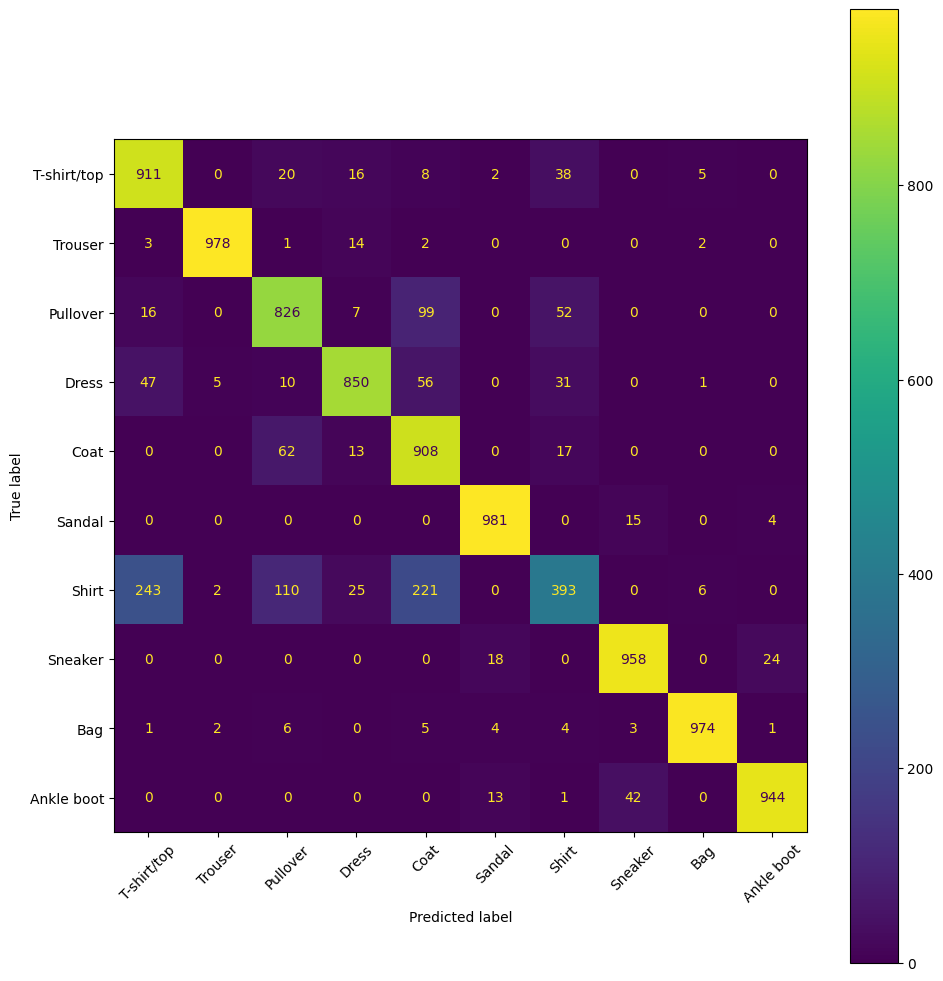

In [12]:
fig,ax=plt.subplots(figsize=(10,10))
ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=names,xticks_rotation=45,ax=ax)
plt.tight_layout(); plt.show()